In [3]:
import torch
import torch.nn.functional as F 
import matplotlib.pyplot 
%matplotlib inline


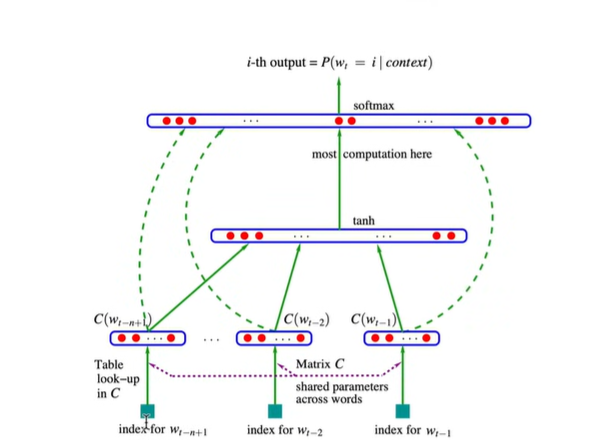

In [4]:
words= open("names.txt", 'r').read().splitlines()

words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [5]:
len(words)

32033

In [6]:
# building the vocab
chars= sorted(list(set(''.join(words))))
stoi={s:i+1 for i,s in enumerate(chars)}
stoi['.']=0
itos={i:s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [11]:

# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words[:5]:
  
  #print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    #print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append
  
X = torch.tensor(X)
Y = torch.tensor(Y)

In [13]:
X.shape, Y.shape, X.dtype, Y.dtype

(torch.Size([32, 3]), torch.Size([32]), torch.int64, torch.int64)

## Pytorch indexing

In [15]:
C = torch.randn((27, 2)) #2d embedding, lookup table

In [ ]:
C[5]
# pay attention to the equalness between two expressions
#indexing is faster, but will leave onehot

tensor([0.6654, 1.9523])

In [ ]:
# F.one_hot(torch.tensor(5),num_classes=27).float() @ C

tensor([0.6654, 1.9523])

In [22]:
C[[5,6,7]]

tensor([[ 0.6654,  1.9523],
        [-0.5320,  0.3333],
        [ 0.4586, -1.1060]])

In [23]:
C[X].shape

torch.Size([32, 3, 2])

In [24]:
X[13,2]

tensor(1)

In [25]:
C[X][13, 2]

tensor([-0.7513, -0.5065])

In [26]:
C[1]

tensor([-0.7513, -0.5065])

## Hidden layer


In [28]:
emb= C[X]
emb.shape

torch.Size([32, 3, 2])

In [30]:
W1=torch.rand((6, 100))
b1= torch.randn(100)

In [35]:
# emb @ W1 + b1 ---> wont work
torch.cat([emb [:, 0, :], emb[:, 1 , :], emb[:, 2, :]], 1).shape

torch.Size([32, 6])

In [38]:
torch.cat(torch.unbind(emb, 1), 1 ).shape

torch.Size([32, 6])

In [45]:
a = torch.arange(18)
a.shape
a.view(3,3,2)
a.view(9,2)

tensor([[ 0,  1],
        [ 2,  3],
        [ 4,  5],
        [ 6,  7],
        [ 8,  9],
        [10, 11],
        [12, 13],
        [14, 15],
        [16, 17]])

In [ ]:
a.storage() #1d vector in the memory
#.view() manipulates internal attributes of the view of the tensor
# storage offset, strides and shapes
# storage is always the same 

# pytorch internals **

C:\Users\m444sa\AppData\Local\Temp\ipykernel_5200\214256462.py:1: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  a.storage()


 0
 1
 2
 3
 4
 5
 6
 7
 8
 9
 10
 11
 12
 13
 14
 15
 16
 17
[torch.storage.TypedStorage(dtype=torch.int64, device=cpu) of size 18]

In [47]:
# anyways
h= torch.tanh(emb.view(-1,6) @  W1 + b1)

In [49]:
h.shape

torch.Size([32, 100])

In [50]:
W2= torch.randn((100,27)) # 27 chrs
b2=torch.randn(27)

In [52]:
logits = h @ W2 + b2

In [53]:
logits.shape

torch.Size([32, 27])

In [54]:
counts=logits.exp()
prob= counts/counts.sum(1, keepdims= True)
prob.shape

torch.Size([32, 27])

In [55]:
Y

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0,  9, 19,
         1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0])

In [60]:
loss= -prob[torch.arange(32), Y].log().mean()
loss

tensor(14.7991)

In [ ]:
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
#splitting the dataset
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [85]:

Xtr.shape, Ytr.shape # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [86]:

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [73]:

sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [90]:

for p in parameters:
  p.requires_grad = True

In [87]:

lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [88]:
lri = []
lossi = []
stepi = []

In [91]:

for i in range(200000):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,))
  
  # forward pass
  emb = C[Xtr[ix]] # (32, 3, 10)
  h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 200)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  #print(loss.item())
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  #lr = lrs[i]
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

#print(loss.item())

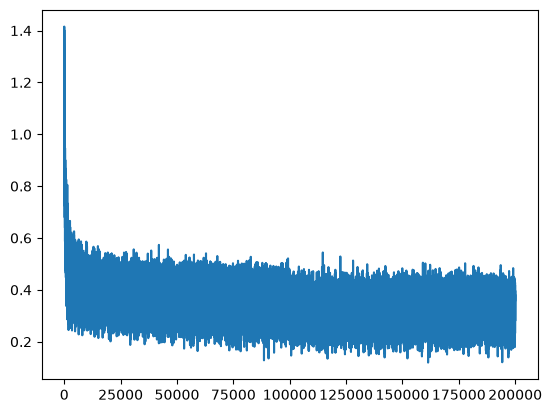

In [94]:
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

plt.plot(stepi, lossi)

In [95]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1231, grad_fn=<NllLossBackward0>)

In [ ]:
# training, dev (vvalidation), test split
# 80, 10, 10 %

